# CA3

### Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

### Reading data

In [9]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

### Data exploration and visualisation

## Basic information about the dataset

In this section, we explore the structure and characteristics of the training data before building any machine learning models. We first inspect the dataset size, column types, missing values, duplicates, and the distribution of the target variable. We then examine the distributions of the numerical features, possible outliers, and correlations between variables.

The goal is to understand the data, identify possible problems, and find patterns that may influence the later cleaning, preprocessing, feature selection, and modelling steps.

### Distribution of the physicochemical features

We examine the distributions of all physicochemical features to better understand their ranges and shapes. This can help us identify skewed distributions, differences in scale, and possible extreme values that may need to be considered during preprocessing and modelling.

Training data shape: (835, 13)
Test data shape: (209, 12)
<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB
Missing values in each column: 

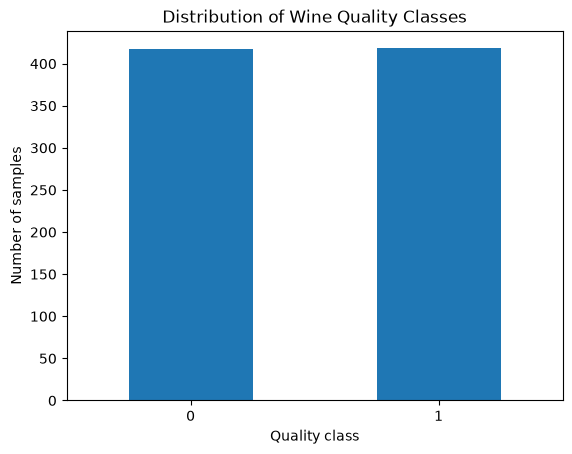

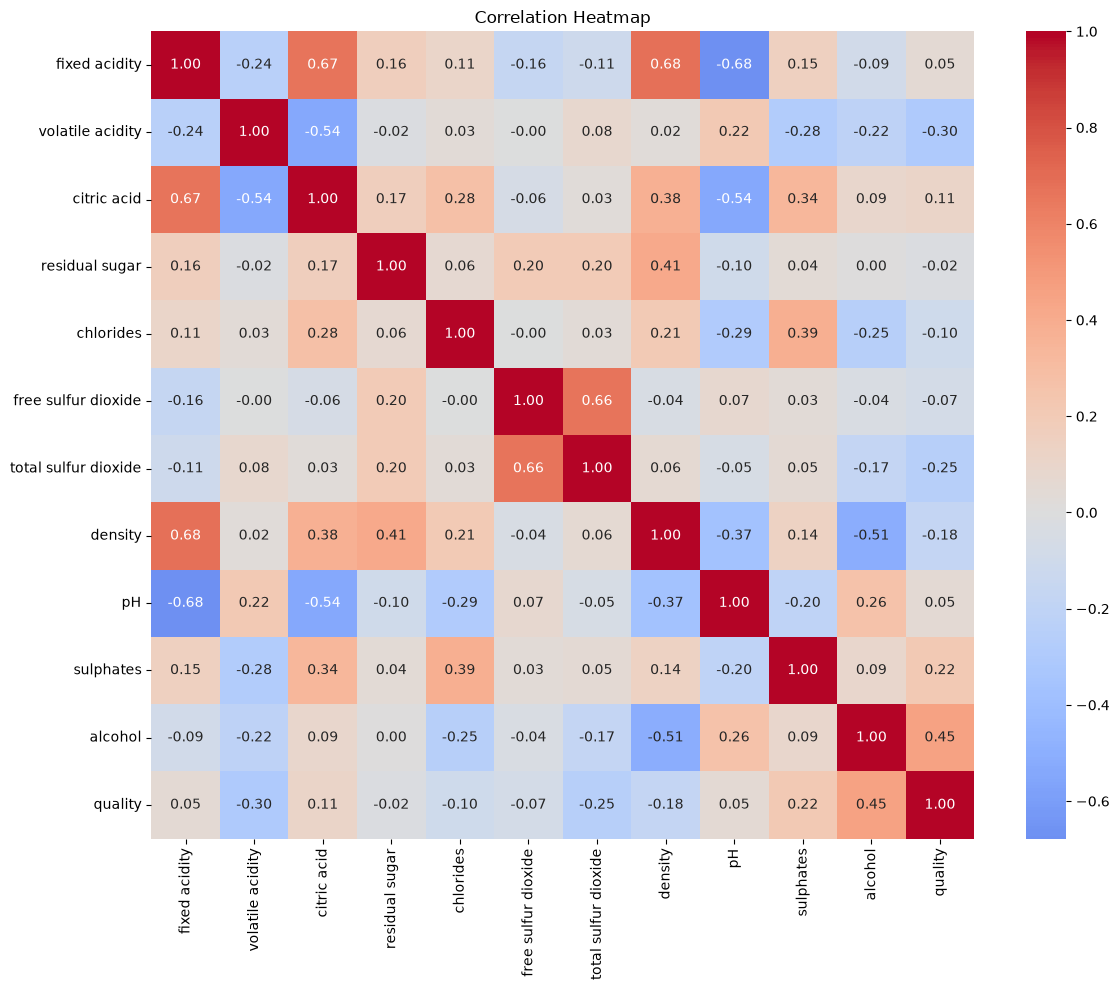

Correlation of each feature with the target: alcohol                 0.451935
sulphates               0.219372
citric acid             0.111017
fixed acidity           0.051339
pH                      0.049578
residual sugar         -0.020452
free sulfur dioxide    -0.074444
chlorides              -0.103287
density                -0.179263
total sulfur dioxide   -0.250267
volatile acidity       -0.302238
Name: quality, dtype: float64


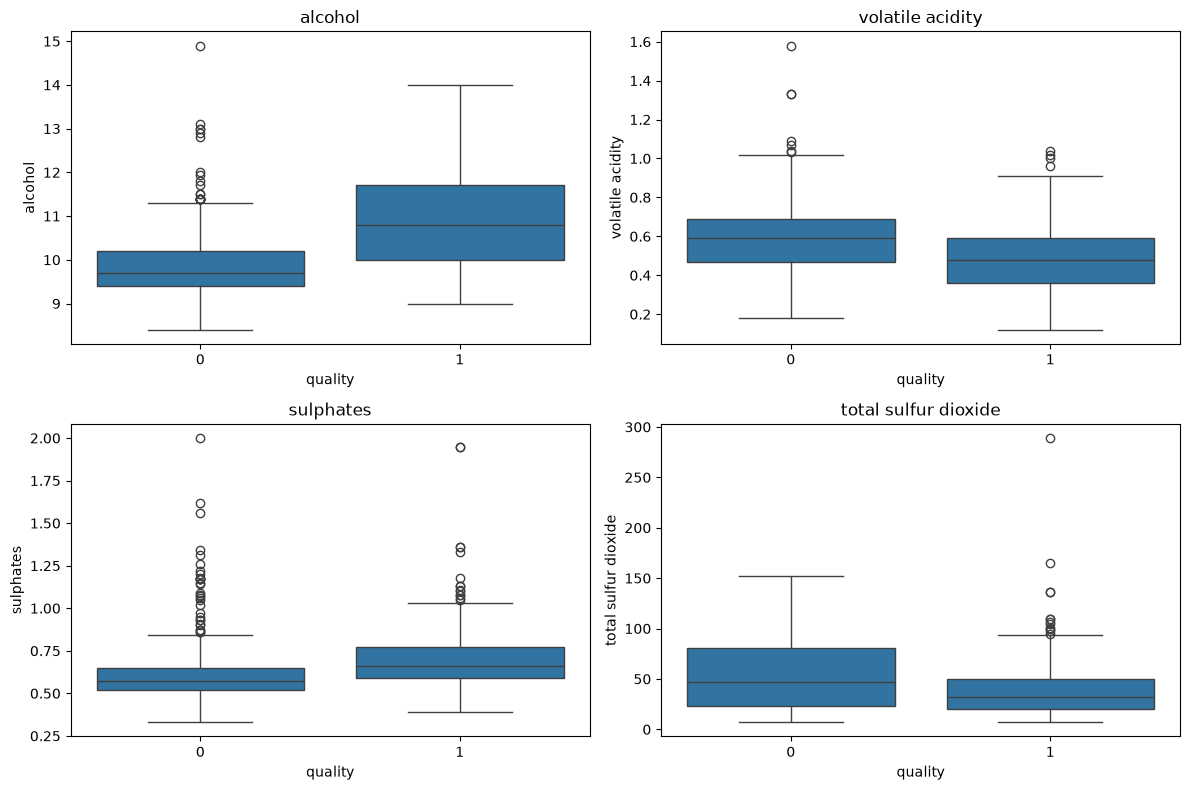

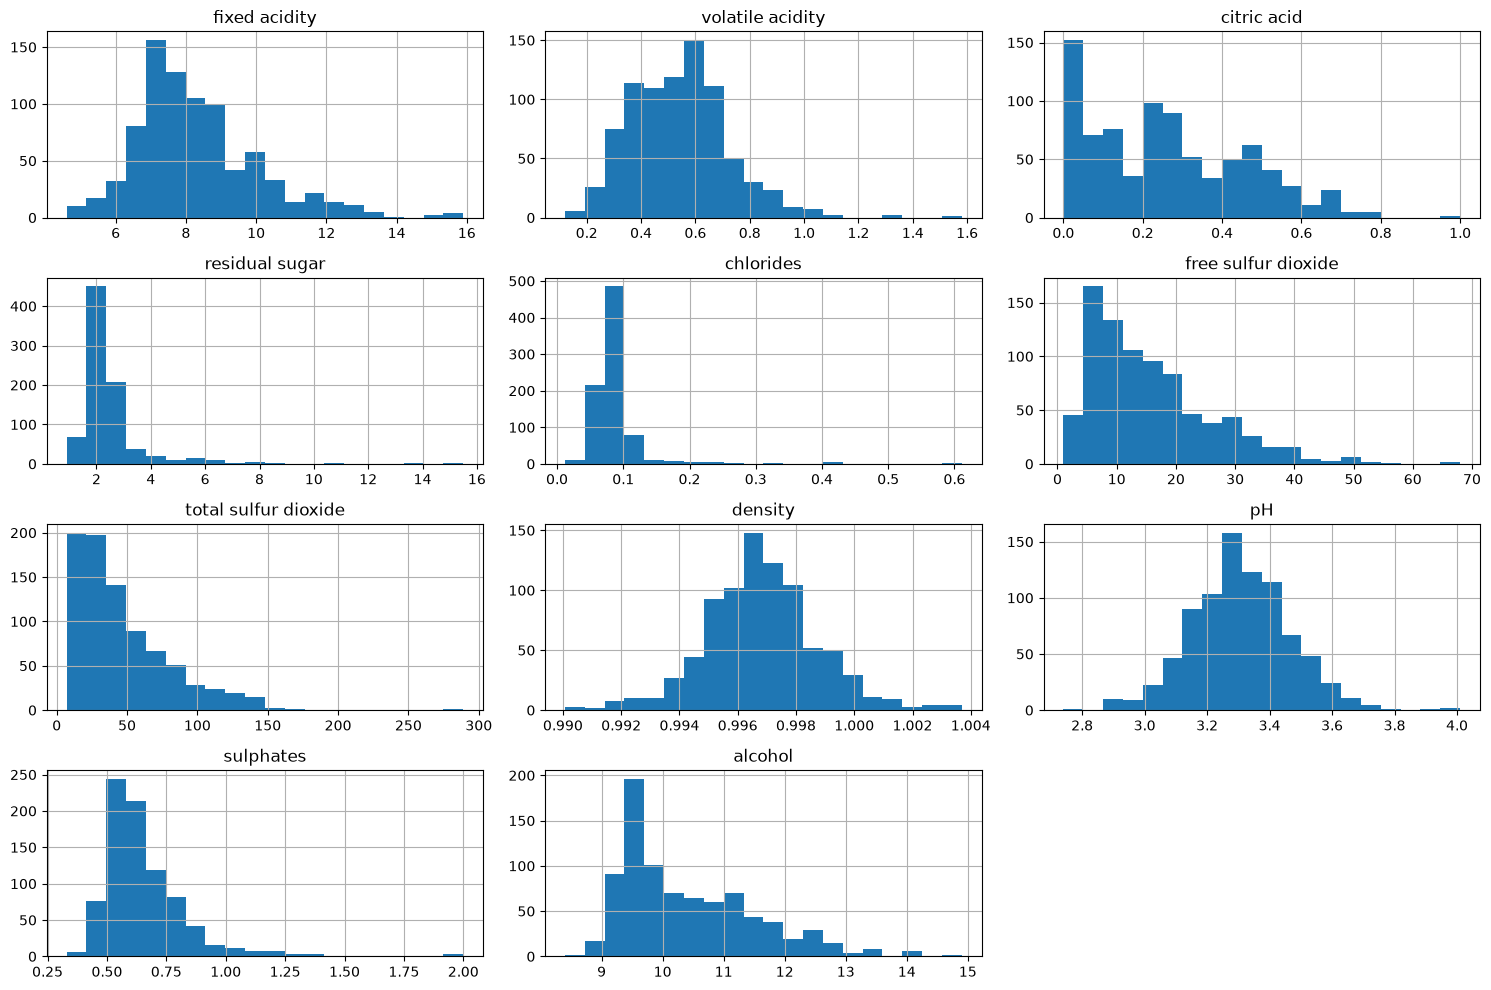

In [10]:
# Check the size of the training and test datasets
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

# Display the first rows of the training data
train_df.head()
# Check column names, data types and missing values
train_df.info()
# Display summary statistics for the numerical features
train_df.describe()
# Check the number of missing values in each column
print("Missing values in each column:", train_df.isnull().sum())
# Check if the dataset contains duplicated rows
print("Number of duplicated rows:", train_df.duplicated().sum())
# Check the number of samples in each quality class
print("Number of samples in each quality class:", train_df["quality"].value_counts())

# Check the percentage of each class
print("Percentage of each quality class:", train_df["quality"].value_counts(normalize=True) * 100)

# Visualize the distribution of the target classes
train_df["quality"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Quality class")
plt.ylabel("Number of samples")
plt.title("Distribution of Wine Quality Classes")
plt.xticks(rotation=0)
plt.show()


# Calculate correlations between the wine features and the target
correlation_data = train_df.drop(columns=["Id"])
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 10)) # Set the figure size for the heatmap

# Create a heatmap to visualize the correlation matrix
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout() # Adjust the layout to prevent overlapping elements
plt.show()

# Show the correlation of each feature with the target
quality_correlation = correlation_matrix["quality"].drop("quality").sort_values(ascending=False)

print("Correlation of each feature with the target:", quality_correlation)


# Visualize the distribution of selected features across different quality classes
selected_features = [
    "alcohol",
    "volatile acidity",
    "sulphates",
    "total sulfur dioxide"
]

plt.figure(figsize=(12, 8))
# Create boxplots for each selected feature against the quality classes
for i, feature in enumerate(selected_features, 1):
    plt.subplot(2, 2, i) # Create a subplot for each feature

    sns.boxplot(
        data=train_df,
        x="quality",
        y=feature
    )

    plt.title(feature)

plt.tight_layout()
plt.show()


# Select only the physicochemical input features
features = train_df.drop(columns=["quality", "Id"])

# Visualize the distribution of all features
features.hist(
    figsize=(15, 10),
    bins=20
)

plt.tight_layout()
plt.show()


### Exploration summary

The dataset contains 835 training samples and 209 test samples. All physicochemical features are numerical, and the training data contains no missing values or duplicated rows. The target classes are almost perfectly balanced, with 418 samples in class 1 and 417 samples in class 0.

The feature distributions show that some variables have different numerical scales and some are skewed or contain extreme values. The correlation analysis also shows that some features are more strongly related to wine quality than others and that some input features are correlated with each other. These observations will be considered in the cleaning, preprocessing, and feature-selection steps.

### Correlation analysis

The correlation analysis shows that `alcohol` has the strongest positive relationship with wine quality, with a correlation of about 0.45. This suggests that wines with higher alcohol content are more often classified as good quality.

`volatile acidity` has the strongest negative correlation with quality, around -0.30, followed by `total sulfur dioxide` at about -0.25. `Sulphates` also shows a moderate positive relationship with quality.

We can also see some relatively strong correlations between the input features themselves. For example, fixed acidity is positively correlated with density and citric acid and negatively correlated with pH. Free sulfur dioxide and total sulfur dioxide are also positively correlated.

These relationships may be useful later when considering feature selection, but we will not remove any features based only on correlation.

### Comparison of important features between quality classes

Based on the correlation analysis, some features appear to have a stronger relationship with wine quality than others. We therefore compare the distributions of selected features between class 0 and class 1 to see whether they provide useful separation between the two quality groups.

### Comparison of selected features

The boxplots show clear differences between the two quality classes for several features.

Wines in class 1 generally have higher alcohol levels than wines in class 0. They also tend to have lower volatile acidity, which supports the negative correlation observed earlier.

Sulphates are slightly higher for class 1, while total sulfur dioxide tends to be lower. However, there is still considerable overlap between the two classes for all features, so none of these variables can separate the classes perfectly on its own.

The plots also show several extreme values, especially for volatile acidity, sulphates, and total sulfur dioxide. These values should be examined further before deciding whether any cleaning is necessary.

### Feature distribution summary

The feature distributions are quite different from each other. Some variables, such as `density` and `pH`, have approximately symmetric distributions, while several others, including `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, and `sulphates`, are clearly right-skewed.

We can also observe that the features have very different numerical ranges. For example, `density` is close to 1, while `total sulfur dioxide` reaches much larger values. This difference in scale will be important when preprocessing the data for scale-sensitive classifiers.

Several features also contain relatively extreme values. However, these observations should not automatically be removed, since they may represent valid wine measurements rather than errors.

### Data cleaning

The dataset contains no missing values or duplicated rows, so no cleaning is required for these issues.

However, the feature distributions show several extreme values. In this section, we examine these observations more closely to determine whether they are likely to be valid measurements or potentially problematic values. We do not remove outliers automatically, since unusual values may still represent real wine measurements.

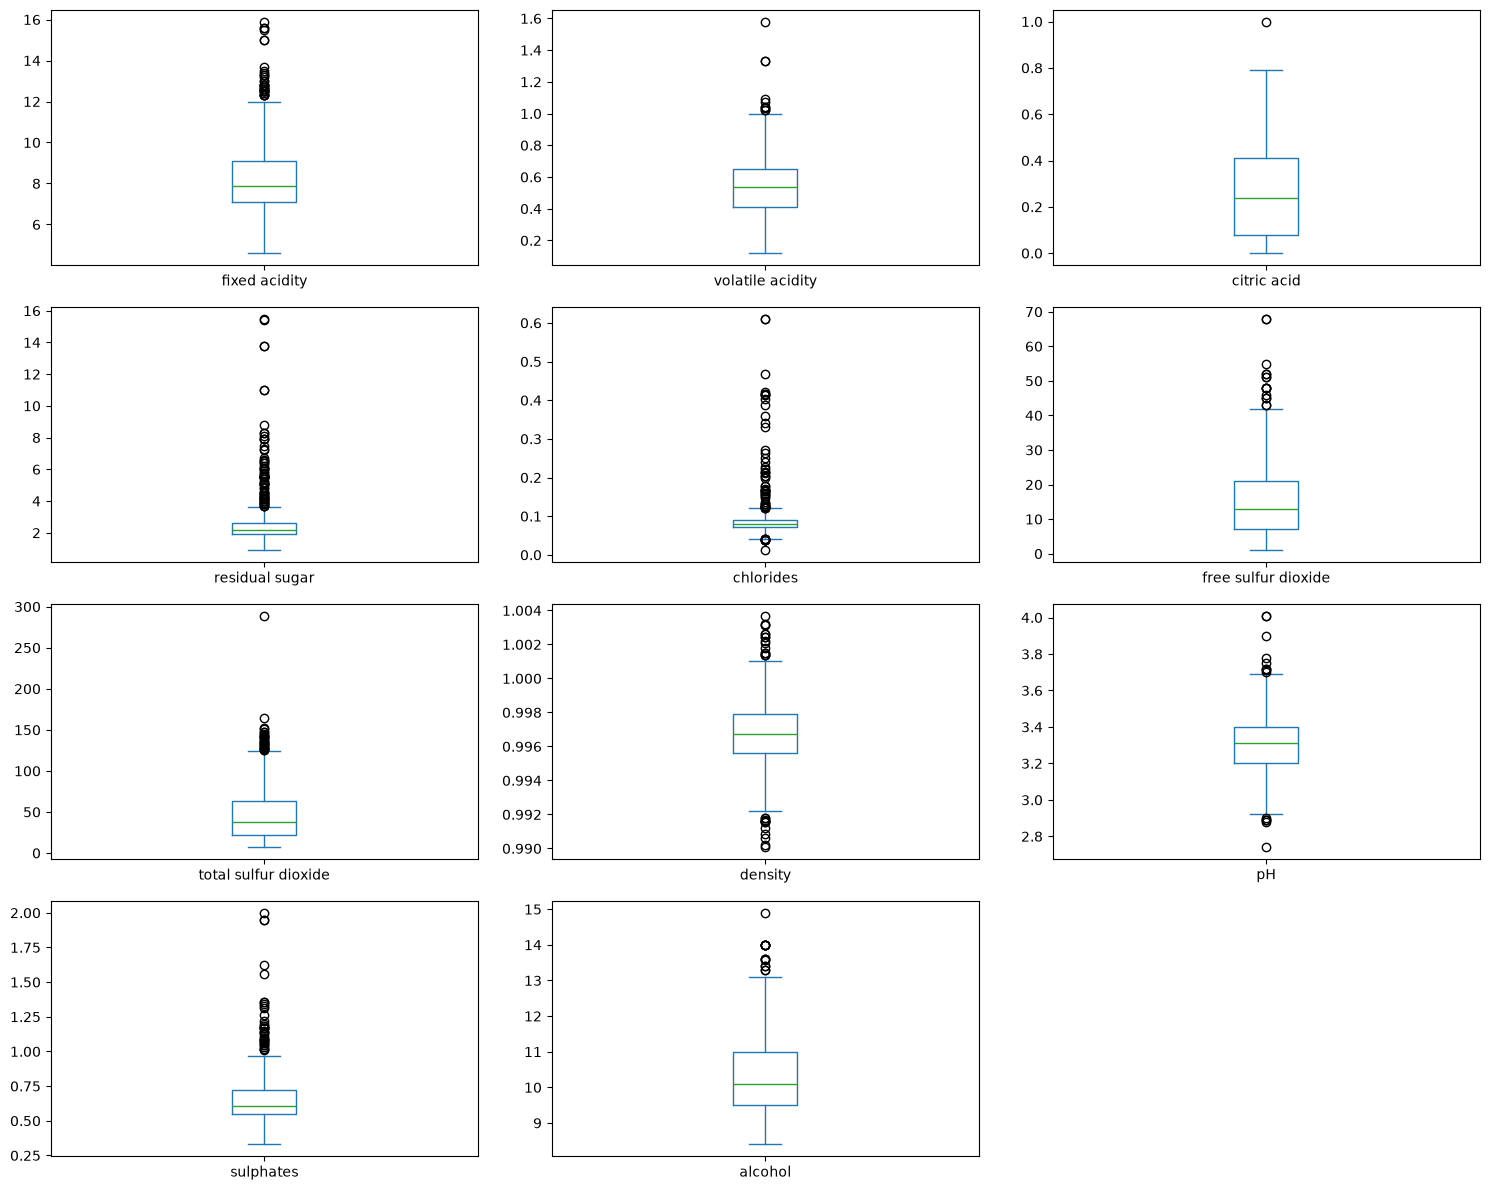

fixed acidity : 33
volatile acidity : 10
citric acid : 1
residual sugar : 76
chlorides : 63
free sulfur dioxide : 16
total sulfur dioxide : 30
density : 29
pH : 15
sulphates : 38
alcohol : 15
                          min        max
fixed acidity         4.60000   15.90000
volatile acidity      0.12000    1.58000
citric acid           0.00000    1.00000
residual sugar        0.90000   15.50000
chlorides             0.01200    0.61100
free sulfur dioxide   1.00000   68.00000
total sulfur dioxide  7.00000  289.00000
density               0.99007    1.00369
pH                    2.74000    4.01000
sulphates             0.33000    2.00000
alcohol               8.40000   14.90000
0    608
1    155
2     51
3     15
4      6
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,outlier_count
167,8.5,0.655,0.49,6.1,0.122,34.0,151.0,1.00100,3.31,1.14,9.3,0,515,4
598,9.9,0.500,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,0,1474,4
676,8.6,0.725,0.24,6.6,0.117,31.0,134.0,1.00140,3.32,1.07,9.3,0,415,4
717,9.2,0.520,1.00,3.4,0.610,32.0,69.0,0.99960,2.74,2.00,9.4,0,151,4
218,9.9,0.500,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,0,1476,4
721,10.2,0.540,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,1,1434,4
88,5.0,0.380,0.01,1.6,0.048,26.0,60.0,0.99084,3.70,0.75,14.0,1,1270,3
20,5.0,0.420,0.24,2.0,0.060,19.0,50.0,0.99170,3.72,0.74,14.0,1,588,3
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557,3
111,15.9,0.360,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,0,652,3


In [11]:
# Visualize possible outliers in all physicochemical features
features = train_df.drop(columns=["quality", "Id"])

features.plot(
    kind="box",
    subplots=True,
    layout=(4, 3),
    figsize=(15, 12)
)

plt.tight_layout()
plt.show()


# Count possible outliers using the IQR method
for feature in features.columns:
    Q1 = features[feature].quantile(0.25)
    Q3 = features[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = features[
        (features[feature] < lower_bound) |
        (features[feature] > upper_bound)
    ]

    print(feature, ":", len(outliers))


    # Check minimum and maximum values for each feature
print(features.agg(["min", "max"]).T)


# Calculate IQR bounds for each feature
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Mark potential outliers
outlier_mask = (features < lower_bound) | (features > upper_bound)

# Count how many features are outliers in each sample
outlier_count = outlier_mask.sum(axis=1)

# Show samples with the largest number of potential outliers
outlier_samples = train_df.copy()
outlier_samples["outlier_count"] = outlier_count

outlier_samples.sort_values(
    "outlier_count",
    ascending=False
)

print(outlier_count.value_counts().sort_index())  # Display the count of samples with each number of outliers

# Show samples that are potential outliers in at least 3 features
suspicious_samples = outlier_samples[outlier_samples["outlier_count"] >= 3]

display(suspicious_samples.sort_values("outlier_count", ascending=False))


### Initial outlier inspection

The boxplots show potential outliers in several physicochemical features. Some variables, especially residual sugar, chlorides, total sulfur dioxide, sulphates, and fixed acidity, contain values that are far from the main part of their distributions.

However, values outside the boxplot whiskers are only potential outliers and are not necessarily incorrect measurements. Therefore, we should inspect the most extreme observations more closely before deciding whether any samples should be removed.

Since the extreme observations may represent valid wine measurements and we do not have sufficient evidence that they are measurement errors, no samples are removed from the dataset.

The IQR analysis identified potential outliers in several features. Residual sugar and chlorides contain the largest number of potential outliers, while citric acid contains very few. However, these observations are not necessarily incorrect measurements. Some features have skewed distributions, which can naturally produce many values outside the IQR limits. Therefore, the extreme values should be examined further before deciding whether any observations should be removed.

### Outlier count per sample

Most samples do not contain potential outliers in any feature. About 73% of the samples have no detected outliers, while only a small number of samples contain potential outliers in three or four features.

Samples that are unusual in several features at the same time may be more suspicious than samples with only one extreme value. Therefore, these observations should be inspected more closely before deciding whether any data should be removed.

### Data cleaning summary

The dataset contains no missing values or duplicated rows. Several features contain potential outliers according to the IQR method, but most samples contain no outliers and only a small number of samples are unusual in several features at the same time.

Since the extreme observations may represent valid wine measurements, we do not remove any samples at this stage. We keep the original data and may later evaluate whether removing suspicious observations improves model performance.

### Data preprocessing and visualisation

## Data preprocessing and visualisation

In this section, we prepare the data for machine learning. We separate the input features from the target variable and remove the `Id` column because it is only an identifier and does not describe the physicochemical properties of the wine.

Some of the classifiers we will evaluate are sensitive to differences in feature scale. Therefore, standardisation will be applied to models such as Logistic Regression, Perceptron, SVM and KNN. Decision Tree and Random Forest models will use the original feature values because tree-based models do not require feature scaling.

To avoid data leakage, the scaler will be fitted only on the training part of each train/validation split.

In [12]:
# Separate features and target
X = train_df.drop(columns=["quality", "Id"])
y = train_df["quality"]

# Save test IDs for the final Kaggle submission
test_ids = test_df["Id"]

# Prepare Kaggle test features
X_test = test_df.drop(columns=["Id"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

X shape: (835, 11)
y shape: (835,)
X_test shape: (209, 11)


### Modelling

We evaluate different classifiers and hyperparameter settings using several train/validation splits of the training data. Different `random_state` values are used so that the model performance is not evaluated based on only one particular split.

For each parameter setting, we calculate the validation accuracy for several splits and compare the average accuracy. The parameter setting with the highest average validation accuracy will be selected.


## Logistic Regression

In [18]:
# Hyperparameter values for Logistic Regression
C_values = [0.01, 0.1, 1, 10, 100]

# Different train/validation splits
random_states = range(10)

logistic_results = []

for C in C_values:
    accuracies = []

    for state in random_states:
        X_train, X_val, y_train, y_val = train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=state,
            stratify=y
        )

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        model = LogisticRegression(
            C=C,
            max_iter=1000
        )

        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_val_scaled)

        accuracy = accuracy_score(y_val, y_pred)
        accuracies.append(accuracy)

    mean_accuracy = np.mean(accuracies)
    std_accuracy = np.std(accuracies)

    logistic_results.append([C, mean_accuracy, std_accuracy])

    print(
        f"C = {C}: "
        f"mean accuracy = {mean_accuracy:.4f}, "
        f"std = {std_accuracy:.4f}"
    )

C = 0.01: mean accuracy = 0.7275, std = 0.0163
C = 0.1: mean accuracy = 0.7375, std = 0.0191
C = 1: mean accuracy = 0.7418, std = 0.0191
C = 10: mean accuracy = 0.7418, std = 0.0179
C = 100: mean accuracy = 0.7414, std = 0.0182


### Logistic Regression results

Logistic Regression was evaluated using several values of the regularisation parameter `C` across 10 different train/validation splits.

The mean validation accuracy increased as `C` increased from 0.01 to 1. The best mean accuracy was approximately 0.742 for both `C = 1` and `C = 10`. Since `C = 10` produced the same mean accuracy with slightly lower variation across the different splits, we selected `C = 10` as the best setting for Logistic Regression.

### Perceptron

In [19]:
# Hyperparameter values for Perceptron
eta0_values = [0.0001, 0.001, 0.01, 0.1]
max_iter_values = [1, 10, 50, 100]

perceptron_results = []

for eta0 in eta0_values:
    for max_iter in max_iter_values:
        accuracies = []

        for state in random_states:
            X_train, X_val, y_train, y_val = train_test_split(
                X,
                y,
                test_size=0.30,
                random_state=state,
                stratify=y
            )

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = Perceptron(
                eta0=eta0,
                max_iter=max_iter,
                random_state=state,
                tol=None
            )

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            accuracy = accuracy_score(y_val, y_pred)
            accuracies.append(accuracy)

        mean_accuracy = np.mean(accuracies)
        std_accuracy = np.std(accuracies)

        perceptron_results.append([
            eta0,
            max_iter,
            mean_accuracy,
            std_accuracy
        ])

        print(
            f"eta0 = {eta0}, "
            f"max_iter = {max_iter}: "
            f"mean accuracy = {mean_accuracy:.4f}, "
            f"std = {std_accuracy:.4f}"
        )

eta0 = 0.0001, max_iter = 1: mean accuracy = 0.6566, std = 0.0453
eta0 = 0.0001, max_iter = 10: mean accuracy = 0.6645, std = 0.0490
eta0 = 0.0001, max_iter = 50: mean accuracy = 0.6697, std = 0.0639
eta0 = 0.0001, max_iter = 100: mean accuracy = 0.6574, std = 0.0501
eta0 = 0.001, max_iter = 1: mean accuracy = 0.6566, std = 0.0453
eta0 = 0.001, max_iter = 10: mean accuracy = 0.6645, std = 0.0490
eta0 = 0.001, max_iter = 50: mean accuracy = 0.6697, std = 0.0639
eta0 = 0.001, max_iter = 100: mean accuracy = 0.6574, std = 0.0501
eta0 = 0.01, max_iter = 1: mean accuracy = 0.6566, std = 0.0453
eta0 = 0.01, max_iter = 10: mean accuracy = 0.6645, std = 0.0490
eta0 = 0.01, max_iter = 50: mean accuracy = 0.6697, std = 0.0639
eta0 = 0.01, max_iter = 100: mean accuracy = 0.6574, std = 0.0501
eta0 = 0.1, max_iter = 1: mean accuracy = 0.6566, std = 0.0453
eta0 = 0.1, max_iter = 10: mean accuracy = 0.6645, std = 0.0490
eta0 = 0.1, max_iter = 50: mean accuracy = 0.6697, std = 0.0639
eta0 = 0.1, max_i

### Perceptron results

The Perceptron classifier was evaluated using different learning rates and numbers of training iterations.

Changing `eta0` did not affect the validation accuracy for a fixed number of iterations. The highest mean validation accuracy was approximately 0.670 with `max_iter = 50`.

However, the Perceptron achieved substantially lower accuracy than the other classifiers and also showed relatively high variation across the different train/validation splits. Therefore, it was not selected as the final model.

### Support Vector Machine

We next evaluate a Support Vector Machine with an RBF kernel. SVM is sensitive to feature scale, so the data are standardised separately within each train/validation split.

Two hyperparameters are evaluated: `C`, which controls the regularisation strength, and `gamma`, which controls how strongly individual training samples influence the decision boundary. Each parameter combination is evaluated across the same 10 train/validation splits.

In [ ]:
# Hyperparameter values for SVM
C_values = [0.1, 1, 10, 100]
gamma_values = [0.01, 0.1, 1]

svm_results = []

for C in C_values:
    for gamma in gamma_values:
        accuracies = []

        for state in random_states:
            X_train, X_val, y_train, y_val = train_test_split(
                X,
                y,
                test_size=0.30,
                random_state=state,
                stratify=y
            )

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = SVC(
                C=C,
                gamma=gamma,
                kernel="rbf"
            )

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            accuracy = accuracy_score(y_val, y_pred)
            accuracies.append(accuracy)

        mean_accuracy = np.mean(accuracies)
        std_accuracy = np.std(accuracies)

        svm_results.append(
            [C, gamma, mean_accuracy, std_accuracy]
        )

        print(
            f"C = {C}, gamma = {gamma}: "
            f"mean accuracy = {mean_accuracy:.4f}, "
            f"std = {std_accuracy:.4f}"
        )

C = 0.1, gamma = 0.01: mean accuracy = 0.7032, std = 0.0332
C = 0.1, gamma = 0.1: mean accuracy = 0.7255, std = 0.0263
C = 0.1, gamma = 1: mean accuracy = 0.6610, std = 0.0394
C = 1, gamma = 0.01: mean accuracy = 0.7255, std = 0.0190
C = 1, gamma = 0.1: mean accuracy = 0.7418, std = 0.0202
C = 1, gamma = 1: mean accuracy = 0.7032, std = 0.0312
C = 10, gamma = 0.01: mean accuracy = 0.7335, std = 0.0199
C = 10, gamma = 0.1: mean accuracy = 0.7363, std = 0.0371
C = 10, gamma = 1: mean accuracy = 0.6924, std = 0.0199
C = 100, gamma = 0.01: mean accuracy = 0.7446, std = 0.0243
C = 100, gamma = 0.1: mean accuracy = 0.7215, std = 0.0318
C = 100, gamma = 1: mean accuracy = 0.6952, std = 0.0249


### SVM results

The SVM classifier was evaluated using different combinations of `C` and `gamma` across 10 train/validation splits.

The best mean validation accuracy was approximately 0.745 using `C = 100` and `gamma = 0.01`. Larger values of `gamma`, especially `gamma = 1`, generally resulted in lower accuracy, suggesting that a smoother decision boundary works better for this dataset.

The selected SVM parameters are therefore `C = 100` and `gamma = 0.01`.

### K-Nearest Neighbors

We next evaluate a K-Nearest Neighbors classifier. KNN is based on distances between samples, so feature scaling is important when the input variables have different numerical ranges.

We evaluate different values of `n_neighbors` and the distance metric parameter `p` across the same 10 train/validation splits. Standardisation is performed separately within each split to avoid data leakage.

In [ ]:
# Hyperparameter values for KNN
n_neighbors_values = [3, 5, 7, 10, 15, 20]
p_values = [1, 2]

knn_results = []

for n_neighbors in n_neighbors_values:
    for p in p_values:
        accuracies = []

        for state in random_states:
            X_train, X_val, y_train, y_val = train_test_split(
                X,
                y,
                test_size=0.30,
                random_state=state,
                stratify=y
            )

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = KNeighborsClassifier(
                n_neighbors=n_neighbors,
                p=p
            )

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            accuracy = accuracy_score(y_val, y_pred)
            accuracies.append(accuracy)

        mean_accuracy = np.mean(accuracies)
        std_accuracy = np.std(accuracies)

        knn_results.append([
            n_neighbors,
            p,
            mean_accuracy,
            std_accuracy
        ])

        print(
            f"n_neighbors = {n_neighbors}, "
            f"p = {p}: "
            f"mean accuracy = {mean_accuracy:.4f}, "
            f"std = {std_accuracy:.4f}"
        )


n_neighbors = 3, p = 1: mean accuracy = 0.6988, std = 0.0284
n_neighbors = 3, p = 2: mean accuracy = 0.6892, std = 0.0248
n_neighbors = 5, p = 1: mean accuracy = 0.7155, std = 0.0291
n_neighbors = 5, p = 2: mean accuracy = 0.7104, std = 0.0359
n_neighbors = 7, p = 1: mean accuracy = 0.7231, std = 0.0226
n_neighbors = 7, p = 2: mean accuracy = 0.7092, std = 0.0355
n_neighbors = 10, p = 1: mean accuracy = 0.7199, std = 0.0236
n_neighbors = 10, p = 2: mean accuracy = 0.7151, std = 0.0278
n_neighbors = 15, p = 1: mean accuracy = 0.7207, std = 0.0224
n_neighbors = 15, p = 2: mean accuracy = 0.7092, std = 0.0241
n_neighbors = 20, p = 1: mean accuracy = 0.7183, std = 0.0247
n_neighbors = 20, p = 2: mean accuracy = 0.7163, std = 0.0247


### KNN results

The K-Nearest Neighbors classifier was evaluated using different values of `n_neighbors` and the distance parameter `p`.

The best mean validation accuracy was approximately 0.723 using `n_neighbors = 7` and `p = 1`, corresponding to Manhattan distance.

Overall, KNN performed worse than Logistic Regression, SVM, Decision Tree, and Random Forest on this dataset.

### Decision Tree

We next evaluate a Decision Tree classifier. Unlike Logistic Regression and SVM, Decision Trees do not require feature standardisation.

We evaluate different values for `criterion`, `max_depth`, and `min_samples_split` across the same 10 train/validation splits. These parameters control how the tree chooses splits and how complex the final tree can become.

In [ ]:
# Hyperparameter values for Decision Tree
criterion_values = ["gini", "entropy"]
max_depth_values = [2, 3, 4, 5, 6, 8]
min_samples_split_values = [2, 5, 10]

tree_results = []

for criterion in criterion_values:
    for max_depth in max_depth_values:
        for min_samples_split in min_samples_split_values:
            accuracies = []

            for state in random_states:
                X_train, X_val, y_train, y_val = train_test_split(
                    X,
                    y,
                    test_size=0.30,
                    random_state=state,
                    stratify=y
                )

                model = DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=max_depth,
                    min_samples_split=min_samples_split,
                    random_state=state
                )

                model.fit(X_train, y_train)

                y_pred = model.predict(X_val)

                accuracy = accuracy_score(y_val, y_pred)
                accuracies.append(accuracy)

            mean_accuracy = np.mean(accuracies)
            std_accuracy = np.std(accuracies)

            tree_results.append([
                criterion,
                max_depth,
                min_samples_split,
                mean_accuracy,
                std_accuracy
            ])

            print(
                f"criterion = {criterion}, "
                f"max_depth = {max_depth}, "
                f"min_samples_split = {min_samples_split}: "
                f"mean accuracy = {mean_accuracy:.4f}, "
                f"std = {std_accuracy:.4f}"
            )

criterion = gini, max_depth = 2, min_samples_split = 2: mean accuracy = 0.6892, std = 0.0213
criterion = gini, max_depth = 2, min_samples_split = 5: mean accuracy = 0.6892, std = 0.0213
criterion = gini, max_depth = 2, min_samples_split = 10: mean accuracy = 0.6892, std = 0.0213
criterion = gini, max_depth = 3, min_samples_split = 2: mean accuracy = 0.7040, std = 0.0270
criterion = gini, max_depth = 3, min_samples_split = 5: mean accuracy = 0.7040, std = 0.0270
criterion = gini, max_depth = 3, min_samples_split = 10: mean accuracy = 0.7040, std = 0.0270
criterion = gini, max_depth = 4, min_samples_split = 2: mean accuracy = 0.7386, std = 0.0186
criterion = gini, max_depth = 4, min_samples_split = 5: mean accuracy = 0.7386, std = 0.0186
criterion = gini, max_depth = 4, min_samples_split = 10: mean accuracy = 0.7386, std = 0.0186
criterion = gini, max_depth = 5, min_samples_split = 2: mean accuracy = 0.7203, std = 0.0210
criterion = gini, max_depth = 5, min_samples_split = 5: mean accura

### Decision Tree results

The Decision Tree classifier was evaluated using different splitting criteria, maximum tree depths, and minimum numbers of samples required to split a node.

The best mean validation accuracy was approximately 0.739 using the Gini criterion with `max_depth = 4`. For this depth, changing `min_samples_split` between 2, 5, and 10 did not affect the result.

Increasing the tree depth beyond 4 generally reduced validation accuracy, suggesting that more complex trees did not generalise as well. We therefore selected `criterion = "gini"`, `max_depth = 4`, and `min_samples_split = 2`.

### Random Forest

We next evaluate a Random Forest classifier. Random Forest combines multiple Decision Trees and can often provide better generalisation than a single tree.

We evaluate different values of `n_estimators` and `max_depth` across the same 10 train/validation splits. Since Random Forest is tree-based, feature standardisation is not required.

In [ ]:
# Hyperparameter values for Random Forest
n_estimators_values = [10, 50, 100, 200]
max_depth_values = [3, 4, 6, 8, None]

rf_results = []

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        accuracies = []

        for state in random_states:
            X_train, X_val, y_train, y_val = train_test_split(
                X,
                y,
                test_size=0.30,
                random_state=state,
                stratify=y
            )

            model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                criterion="gini",
                random_state=state
            )

            model.fit(X_train, y_train)

            y_pred = model.predict(X_val)

            accuracy = accuracy_score(y_val, y_pred)
            accuracies.append(accuracy)

        mean_accuracy = np.mean(accuracies)
        std_accuracy = np.std(accuracies)

        rf_results.append([
            n_estimators,
            max_depth,
            mean_accuracy,
            std_accuracy
        ])

        print(
            f"n_estimators = {n_estimators}, "
            f"max_depth = {max_depth}: "
            f"mean accuracy = {mean_accuracy:.4f}, "
            f"std = {std_accuracy:.4f}"
        )

n_estimators = 10, max_depth = 3: mean accuracy = 0.7327, std = 0.0309
n_estimators = 10, max_depth = 4: mean accuracy = 0.7398, std = 0.0323
n_estimators = 10, max_depth = 6: mean accuracy = 0.7490, std = 0.0232
n_estimators = 10, max_depth = 8: mean accuracy = 0.7434, std = 0.0260
n_estimators = 10, max_depth = None: mean accuracy = 0.7418, std = 0.0205
n_estimators = 50, max_depth = 3: mean accuracy = 0.7466, std = 0.0219
n_estimators = 50, max_depth = 4: mean accuracy = 0.7490, std = 0.0220
n_estimators = 50, max_depth = 6: mean accuracy = 0.7506, std = 0.0247
n_estimators = 50, max_depth = 8: mean accuracy = 0.7518, std = 0.0253
n_estimators = 50, max_depth = None: mean accuracy = 0.7625, std = 0.0224
n_estimators = 100, max_depth = 3: mean accuracy = 0.7486, std = 0.0213
n_estimators = 100, max_depth = 4: mean accuracy = 0.7518, std = 0.0250
n_estimators = 100, max_depth = 6: mean accuracy = 0.7506, std = 0.0241
n_estimators = 100, max_depth = 8: mean accuracy = 0.7622, std = 0.0

### Random Forest results

The Random Forest classifier was evaluated using different numbers of trees and different maximum tree depths.

The best mean validation accuracy was approximately 0.765. The configurations with no maximum depth performed particularly well. Although `n_estimators = 200` gave the highest mean accuracy, `n_estimators = 100` produced almost the same mean accuracy with lower variation across the train/validation splits.

We therefore selected `n_estimators = 100` and `max_depth = None` as the preferred Random Forest configuration.

### Final evaluation

## Final evaluation

In this section, we compare the best configuration of each classifier based on their mean validation accuracy across the repeated train/validation splits.

The final classifier is selected based on both predictive performance and consistency across the different splits.

,Classifier,Mean Accuracy,Std Accuracy
3,Random Forest,0.7649,0.0256
1,SVM,0.7446,0.0243
0,Logistic Regression,0.7418,0.0179
2,Decision Tree,0.7386,0.0186
4,KNN,0.7231,0.0226
5,Perceptron,0.6697,0.0639


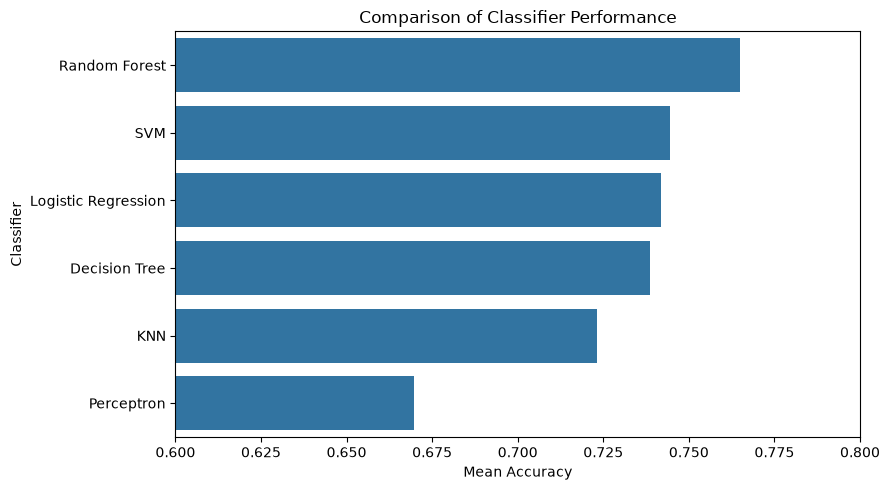

In [15]:
model_comparison = pd.DataFrame({
    "Classifier": [
        "Logistic Regression",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "Perceptron"
    ],
    "Mean Accuracy": [
        0.7418,
        0.7446,
        0.7386,
        0.7649,
        0.7231,
        0.6697
    ],
    "Std Accuracy": [
        0.0179,
        0.0243,
        0.0186,
        0.0256,
        0.0226,
        0.0639
    ]
})

model_comparison = model_comparison.sort_values(
    "Mean Accuracy",
    ascending=False
)

display(model_comparison)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Mean Accuracy",
    y="Classifier"
)

plt.title("Comparison of Classifier Performance")
plt.xlim(0.6, 0.8)
plt.tight_layout()
plt.show()


### Final model selection

Random Forest achieved the highest overall validation performance among the evaluated classifiers. The selected configuration achieved a mean validation accuracy of approximately 0.765 with relatively low variation across the repeated splits.

Therefore, Random Forest with `n_estimators = 200` and `max_depth = None` (`n_estimators = 100` and `max_depth = None` also was a good choice considering the less n_estimator) is selected as the final model.

The final model will now be trained using the complete training dataset before generating predictions for the Kaggle test set.

### Kaggle submission

The selected Random Forest classifier is now retrained using the complete training dataset with the best hyperparameter configuration identified during validation.

Since Random Forest does not require feature standardisation, the original feature values are used. The trained model is then used to predict the quality classes for the Kaggle test set.

## Check the Kaggle submission template

In [20]:
# Display the first rows of the Kaggle submission template
display(sample_submission.head())

# Show the column names of the submission file
print("Submission columns:", sample_submission.columns.tolist())

# Show the number of rows and columns
print("Submission shape:", sample_submission.shape)

,ID,quality
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Submission columns: ['ID', 'quality']
Submission shape: (209, 2)


## Train the final Random Forest

In [21]:
# Create the final Random Forest classifier using
# the best hyperparameters found during model evaluation
final_model = RandomForestClassifier(
    criterion="gini",
    n_estimators=200,
    max_depth=None,
    random_state=1
)

# Train the final model using the complete training dataset
# X contains the 11 physicochemical input features
# y contains the corresponding wine quality labels
final_model.fit(X, y)

# Use the trained model to predict the quality
# of all samples in the Kaggle test dataset
test_predictions = final_model.predict(X_test)

# Check that the number of predictions matches
# the number of samples in the test dataset
print("Number of predictions:", len(test_predictions))

# Check the distribution of the predicted classes
print(
    "Predicted class distribution:",
    np.unique(test_predictions, return_counts=True)
)

Number of predictions: 209
Predicted class distribution: (array([0, 1]), array([101, 108]))


## Create the submission DataFrame

In [30]:
# Create the final Kaggle submission
# Use the ID values from the provided sample submission,
# because these are the IDs expected by Kaggle.
submission = pd.DataFrame({
    "Id": sample_submission["ID"],
    "quality": test_predictions
})

# Display the first rows
display(submission.head())

# Check the final structure
print("Submission columns:", submission.columns.tolist())
print("Submission shape:", submission.shape)

# Check for missing values
print("Missing predictions:", submission["quality"].isnull().sum())

# Check the predicted classes
print("Unique predictions:", submission["quality"].unique())

,Id,quality
0,0,1
1,1,1
2,2,0
3,3,0
4,4,0


Submission columns: ['Id', 'quality']
Submission shape: (209, 2)
Missing predictions: 0
Unique predictions: [1 0]


## Final checks before saving

In [31]:
# Check that the submission contains the correct number of rows
print(
    "Correct number of rows:",
    len(submission) == len(X_test)
)

# Check that there are no missing predictions
print(
    "Missing predictions:",
    submission["quality"].isnull().sum()
)

# Check that the model predicted only the two expected classes
print(
    "Unique predictions:",
    submission["quality"].unique()
)

# Display the first rows of the final Kaggle submission
display(submission.head())

# Display the last rows as an additional check
display(submission.tail())

Correct number of rows: True
Missing predictions: 0
Unique predictions: [1 0]


,Id,quality
0,0,1
1,1,1
2,2,0
3,3,0
4,4,0


,Id,quality
204,204,1
205,205,0
206,206,1
207,207,1
208,208,1


## Save the Kaggle CSV

In [33]:
# Save the completed submission as a CSV file
# index=False prevents Pandas from adding an extra index column
submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv has been created successfully.")

submission.csv has been created successfully.


### Kaggle submission summary

The final Random Forest classifier was trained using the complete training dataset and used to predict the quality labels for all 209 samples in the Kaggle test set.

The predictions contained both expected classes, with 101 samples predicted as class 0 and 108 samples predicted as class 1. The submission was checked for the correct number of rows and missing values before being saved as `submission.csv`.

The final submission contains the required `ID` and `quality` columns and is ready for upload to Kaggle.

In [34]:
# Create a Random Forest classifier with 100 trees
rf_100 = RandomForestClassifier(
    criterion="gini",
    n_estimators=100,
    max_depth=None,
    random_state=1
)

# Train the model using the complete training dataset
rf_100.fit(X, y)

# Predict the quality classes for the Kaggle test dataset
predictions_100 = rf_100.predict(X_test)

# Check the number and distribution of predictions
print("Number of predictions:", len(predictions_100))
print(
    "Predicted class distribution:",
    np.unique(predictions_100, return_counts=True)
)

# Create a new submission using the official Kaggle template
submission_100 = sample_submission.copy()

# Rename the ID column to the exact name required by Kaggle
submission_100 = submission_100.rename(columns={"ID": "Id"})

# Add predictions from the 100-tree Random Forest
submission_100["quality"] = predictions_100

# Display the first rows
display(submission_100.head())

# Check the submission
print("Submission shape:", submission_100.shape)
print("Missing predictions:", submission_100["quality"].isnull().sum())
print("Unique predictions:", submission_100["quality"].unique())

# Save the 100-tree submission as a separate CSV file
submission_100.to_csv(
    "submission_rf_100.csv",
    index=False
)

print("submission_rf_100.csv has been created.")

Number of predictions: 209
Predicted class distribution: (array([0, 1]), array([103, 106]))


,Id,quality
0,0,1
1,1,1
2,2,0
3,3,0
4,4,0


Submission shape: (209, 2)
Missing predictions: 0
Unique predictions: [1 0]
submission_rf_100.csv has been created.


In [ ]:
# Create a StandardScaler for the SVM model
scaler = StandardScaler()

# Fit the scaler using the complete training dataset
# and standardise all training features
X_scaled = scaler.fit_transform(X)

# Standardise the Kaggle test data using the same
# scaling parameters learned from the training data
X_test_scaled = scaler.transform(X_test)

# Create the final SVM classifier using the
# best hyperparameters found during validation
svm_final = SVC(
    C=100,
    gamma=0.01,
    kernel="rbf"
)

# Train the SVM model using the complete scaled training dataset
svm_final.fit(X_scaled, y)

# Predict the quality classes for all Kaggle test samples
svm_predictions = svm_final.predict(X_test_scaled)

# Check the number of predictions
print("Number of predictions:", len(svm_predictions))

# Check the distribution of predicted classes
print(
    "Predicted class distribution:",
    np.unique(svm_predictions, return_counts=True)
)

# Create a copy of the official Kaggle submission template
submission_svm = sample_submission.copy()

# Rename the ID column to the exact name required by Kaggle
submission_svm = submission_svm.rename(columns={"ID": "Id"})

# Replace the example quality values with the SVM predictions
submission_svm["quality"] = svm_predictions

# Display the first rows of the SVM submission
display(submission_svm.head())

# Check the final submission dimensions
print("Submission shape:", submission_svm.shape)

# Check that there are no missing predictions
print(
    "Missing predictions:",
    submission_svm["quality"].isnull().sum()
)

# Check that only the expected binary classes are present
print(
    "Unique predictions:",
    submission_svm["quality"].unique()
)

# Save the SVM predictions as a separate Kaggle submission file
submission_svm.to_csv(
    "submission_svm.csv",
    index=False
)

print("submission_svm.csv has been created successfully.")